# Benchmark: treatment effects under confounding

This study asks how well the average treatment effect (ATE) and the
conditional treatment effect $\tau(x)$ are recovered when every confounder
is measured, using mboostrs and other learners as the nuisance models. The
data are simulated, so the true effects are known. Three designs vary how
hard the adjustment is: smooth confounding, confounding and effect
modification through thresholds, and the smooth design with propensities
pushed towards 0 and 1 (weak overlap).

The ATE is estimated by augmented inverse-probability weighting (AIPW): with
out-of-fold predictions $\hat\mu_0(x)$, $\hat\mu_1(x)$ of the outcome under
each treatment and $\hat e(x)$ of the treatment probability,

$$
\hat\tau = \frac1n\sum_i \Big[\hat\mu_1(x_i) - \hat\mu_0(x_i)
 + \frac{t_i\,(y_i - \hat\mu_1(x_i))}{\hat e(x_i)}
 - \frac{(1 - t_i)(y_i - \hat\mu_0(x_i))}{1 - \hat e(x_i)}\Big],
$$

with the standard error from the spread of the bracketed scores. The
estimate is consistent when either the outcome models or the propensity
model is right, and its interval is valid when both converge fast enough.
mboostrs provides it as `mb.aipw`, with its own cross-fitting and tuning; for
the other libraries the same estimator is written once in the harness
(`benches/bench_causal.py`) with 5 folds, one outcome model per treatment arm
and the propensities clipped to $[0.01, 0.99]$, the same clipping passed to
`mb.aipw`.

Four dedicated causal-inference libraries run on the same replicates:
EconML's `LinearDML` (double machine learning with an effect linear in the
covariates) and `CausalForestDML` (a causal forest on the residualized
outcome), DoubleML's interactive regression model (AIPW with cross-fitting),
and the causal forest of the R package grf. The EconML and DoubleML nuisance
models are LightGBM with 300 trees of 15 leaves; grf grows its own forests.
Each is used with its documented defaults.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how accurately the treatment effect is recovered when every confounder is measured |
| **Observed response** | a simulated continuous outcome after a binary treatment |
| **Estimand** | the average treatment effect (bias, RMSE, 95% interval coverage) and the conditional effect tau(x) (root mean squared error, PEHE) |
| **Units** | outcome units |
| **Sampling unit** | one simulated unit; 2,000 per replicate, with tau(x) scored on 4,000 fresh units |
| **Dependence** | independent units by construction |
| **Split / resampling unit** | 5-fold cross-fitting of the nuisance models within each replicate; 12 replicates per design |
| **Tuning** | mb.aipw's own inner cross-validation; a 20% validation split for the tree nuisance models; REML for mgcv |
| **Uncertainty** | Monte Carlo standard errors over replicates |
| **Claim type** | causal and methodological: estimator properties under no unmeasured confounding, which holds by construction |
:::

In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl

bench = json.loads(Path("bench_causal.json").read_text())
rows = [r for r in bench["results"] if "failure" not in r]
failures = [r for r in bench["results"] if "failure" in r]
causal = pl.DataFrame(rows, infer_schema_length=None)
true_ate = bench["protocol"]["true_ate"]
(f"{causal.height} estimates, {len(failures)} failed; "
 f"true ATE: " + ", ".join(f"{k} {v:.3f}" for k, v in true_ate.items()))

'684 estimates, 0 failed; true ATE: smooth 1.000, threshold 1.000, weak_overlap 1.000'

## The designs

| Design | Treatment assignment | Outcome without treatment | Effect $\tau(x)$ |
|---|---|---|---|
| smooth | logit $0.8\sin 1.5x_1 + 0.5x_2 - 0.4(x_3^2 - 4/3)$ | $\sin 1.5x_1 + 0.5x_2 + 0.4x_3^2 + 0.5x_4$ | $1 + 0.5\,x_1$ |
| threshold | logit $1.2\,[x_1>0] - [x_2>0.5,\ x_3<0] + 0.3x_4$ | $1.5\,[x_1>0,\ x_2>0] + 0.6x_3 + 0.8\,[x_4>1]$ | $0.5 + [x_4>0]$ |
| weak overlap | the smooth design's logit multiplied by 2.5 | as smooth | as smooth |

The confounders are $x_1$ to $x_3$ (they drive both treatment and outcome);
the effect modifier is $x_1$ in the smooth designs and $x_4$ in the
threshold design. The difference in means, which ignores the covariates, is
included to show how much confounding there is to remove.

## The average treatment effect

In [2]:
ate = (causal.filter(pl.col("se").is_not_null() | (pl.col("method") == "difference in means"))
       .group_by("design", "method")
       .agg(pl.col("error").mean().alias("bias"),
            (pl.col("error").std() / pl.len().sqrt()).alias("bias se"),
            (pl.col("error") ** 2).mean().sqrt().alias("RMSE"),
            pl.col("covered").mean().alias("95% coverage"),
            pl.col("se").mean().alias("mean SE"),
            pl.col("ate").std().alias("SD of estimates"),
            pl.col("time").mean().alias("seconds"))
       .sort("design", "RMSE"))


In [3]:
from bench_tables import table as annotated

# Bias is judged against 0 and coverage against the nominal 0.95, so those
# columns mark the value closest to the target rather than the extreme.

DESIGN = {"smooth": "smooth confounding", "threshold": "threshold confounding",
          "weak_overlap": "weak overlap"}
annotated(
    ate.with_columns(pl.col("design").replace(DESIGN)),
    title="Average treatment effect: bias, error and interval coverage",
    subtitle="12 replicates per design; 2,000 units each; outcome units",
    group="design",
    labels={"bias": "bias", "bias se": "se", "RMSE": "RMSE ↓", "95% coverage": "coverage",
            "mean SE": "mean SE", "SD of estimates": "SD of estimates", "seconds": "s"},
    spanners={"Estimate minus true ATE": ["bias", "bias se", "RMSE"],
              "95% interval": ["95% coverage", "mean SE", "SD of estimates"]},
    better={"bias": 0.0, "RMSE": "min", "95% coverage": 0.95},
    formats={"seconds": 1},
    notes=["bias: mean of estimate minus true ATE over the replicates, with its standard "
           "error (se). RMSE: root mean squared error of the estimate. coverage: share of "
           "replicates whose 95% interval contains the true ATE; with 12 replicates its "
           "standard error is about 0.06. mean SE: the average reported standard error; "
           "SD of estimates: their spread over replicates, which a well-calibrated SE matches.",
           "Bold: within each design, the bias closest to 0, the lowest RMSE and the "
           "coverage closest to 0.95. The difference in means has no interval. s: mean "
           "seconds per estimate. Source: bench_causal.json, written by benches/bench_causal.py."])

GT(_tbl_data=shape: (36, 9)
┌────────────┬───────────┬───────────┬──────────┬───┬───────────┬──────────┬───────────┬───────────┐
│ design     ┆ method    ┆ bias      ┆ bias se  ┆ … ┆ 95%       ┆ mean SE  ┆ SD of     ┆ seconds   │
│ ---        ┆ ---       ┆ ---       ┆ ---      ┆   ┆ coverage  ┆ ---      ┆ estimates ┆ ---       │
│ str        ┆ str       ┆ f64       ┆ f64      ┆   ┆ ---       ┆ f64      ┆ ---       ┆ f64       │
│            ┆           ┆           ┆          ┆   ┆ f64       ┆          ┆ f64       ┆           │
╞════════════╪═══════════╪═══════════╪══════════╪═══╪═══════════╪══════════╪═══════════╪═══════════╡
│ smooth con ┆ mboostrs  ┆ 0.006751  ┆ 0.017    ┆ … ┆ 0.916667  ┆ 0.05045  ┆ 0.058889  ┆ 3.362869  │
│ founding   ┆ aipw      ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│            ┆ (smooth)  ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ smooth con ┆ LightGBM  ┆ -0.002934 ┆ 0.017307 ┆ … ┆ 0.916667  ┆ 0.052587 ┆ 0.059954  ┆ 1.646931  │
│ founding   ┆ AIPW      ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ smooth con ┆ XGBoost   ┆ -0.006465 ┆ 0.017296 ┆ … ┆ 0.916667  ┆ 0.052772 ┆ 0.059916  ┆ 3.629648  │
│ founding   ┆ AIPW      ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ smooth con ┆ mgcv AIPW ┆ 0.000943  ┆ 0.017464 ┆ … ┆ 0.916667  ┆ 0.053114 ┆ 0.060497  ┆ 28.808333 │
│ founding   ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ smooth con ┆ EBM AIPW  ┆ 0.005916  ┆ 0.017743 ┆ … ┆ 0.916667  ┆ 0.054022 ┆ 0.061462  ┆ 498.42102 │
│ founding   ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆ 2         │
│ …          ┆ …         ┆ …         ┆ …        ┆ … ┆ …         ┆ …        ┆ …         ┆ …         │
│ weak       ┆ APLR AIPW ┆ 0.06551   ┆ 0.029879 ┆ … ┆ 0.75      ┆ 0.091511 ┆ 0.103504  ┆ 85.924338 │
│ overlap    ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ weak       ┆ mgcv AIPW ┆ -0.02907  ┆ 0.036318 ┆ … ┆ 0.833333  ┆ 0.094973 ┆ 0.12581   ┆ 27.0865   │
│ overlap    ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ weak       ┆ mboostrs  ┆ -0.193019 ┆ 0.02286  ┆ … ┆ 0.166667  ┆ 0.076003 ┆ 0.079189  ┆ 0.968755  │
│ overlap    ┆ aipw      ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│            ┆ (linear)  ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ weak       ┆ DoubleML  ┆ -0.047961 ┆ 0.06899  ┆ … ┆ 1.0       ┆ 0.225772 ┆ 0.238987  ┆ 2.562265  │
│ overlap    ┆ IRM       ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│            ┆ (AIPW)    ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ weak       ┆ differenc ┆ 1.465288  ┆ 0.020417 ┆ … ┆ null      ┆ null     ┆ 0.070727  ┆ null      │
│ overlap    ┆ e in      ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│            ┆ means     ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
└────────────┴───────────┴───────────┴──────────┴───┴───────────┴──────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x111f97650>, _boxhead=Boxhead([ColInfo(var='design', type=<ColInfoTypeEnum.row_group: 3>, column_label='design', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='bias', type=<ColInfoTypeEnum.default: 1>, column_label='bias', column_align='right', column_width=None), ColInfo(var='bias se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='RMSE', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE ↓', column_align='right', column_width=None), ColInfo(var='95% coverage', type=<ColInfoTypeEnum.default: 1>, co

In [4]:
def pick(design, method, column):
    return ate.filter((pl.col("design") == design) & (pl.col("method") == method))[column][0]


naive_bias = {d: pick(d, "difference in means", "bias") for d in true_ate}
best_rmse = {d: ate.filter(pl.col("design") == d)["method"][0] for d in true_ate}
mb_smooth_bias = {d: pick(d, "mboostrs aipw (smooth)", "bias") for d in true_ate}
mb_smooth_cov = {d: pick(d, "mboostrs aipw (smooth)", "95% coverage") for d in true_ate}
mb_smooth_rmse = {d: pick(d, "mboostrs aipw (smooth)", "RMSE") for d in true_ate}
mb_linear_bias = {d: pick(d, "mboostrs aipw (linear)", "bias") for d in true_ate}
ebm_time = pick("smooth", "EBM AIPW", "seconds")
mb_time = pick("smooth", "mboostrs aipw (smooth)", "seconds")

Confounding moves the difference in means by
{eval}`round(naive_bias["smooth"], 2)` in the smooth design,
{eval}`round(naive_bias["threshold"], 2)` in the threshold design and
{eval}`round(naive_bias["weak_overlap"], 2)` with weak overlap, against true
effects near 1. The adjusted estimators remove most of it. The lowest RMSE
is {eval}`best_rmse["smooth"]`'s in the smooth design,
{eval}`best_rmse["threshold"]`'s in the threshold design and
{eval}`best_rmse["weak_overlap"]`'s with weak overlap. `mb.aipw` with smooth
nuisance models has bias {eval}`round(mb_smooth_bias["smooth"], 3)`,
{eval}`round(mb_smooth_bias["threshold"], 3)` and
{eval}`round(mb_smooth_bias["weak_overlap"], 3)` in the three designs, and its
95% interval covers the true ATE in
{eval}`round(100 * mb_smooth_cov["smooth"])`%,
{eval}`round(100 * mb_smooth_cov["threshold"])`% and
{eval}`round(100 * mb_smooth_cov["weak_overlap"])`% of the replicates (12 per
design, so a coverage estimate has a standard error of about 6 points). With
linear nuisance models, which cannot represent the sine and the parabola,
its bias in the smooth design is {eval}`round(mb_linear_bias["smooth"], 3)`.
It takes {eval}`round(mb_time, 1)` seconds per estimate, against
{eval}`round(ebm_time)` for the same estimator built on EBM.

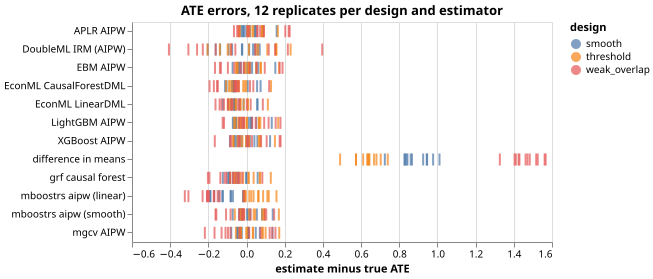

In [5]:
spread = causal.filter(pl.col("se").is_not_null() | (pl.col("method") == "difference in means"))
alt.Chart(spread).mark_tick(thickness=2, size=12).encode(
    x=alt.X("error:Q", title="estimate minus true ATE"),
    y=alt.Y("method:N", title=None),
    color=alt.Color("design:N", title="design"),
).properties(width=420, height=220,
             title="ATE errors, 12 replicates per design and estimator")

The dedicated libraries reach the same accuracy as the hand-written AIPW
estimators in the smooth and threshold designs (RMSE between
{eval}`round(min(pick(d, m, "RMSE") for d in ("smooth", "threshold") for m in ("EconML LinearDML", "EconML CausalForestDML", "grf causal forest")), 3)`
and
{eval}`round(max(pick(d, m, "RMSE") for d in ("smooth", "threshold") for m in ("EconML LinearDML", "EconML CausalForestDML", "DoubleML IRM (AIPW)", "grf causal forest")), 3)`),
and their intervals differ more than their estimates. `CausalForestDML`'s
95% interval covered the true ATE in every replicate of every design, with a
mean standard error of {eval}`round(pick("smooth", "EconML CausalForestDML", "mean SE"), 3)`
in the smooth design against a spread of estimates of
{eval}`round(pick("smooth", "EconML CausalForestDML", "SD of estimates"), 3)`:
the interval is about four times wider than it needs to be. `LinearDML`
covered {eval}`round(100 * pick("smooth", "EconML LinearDML", "95% coverage"))`% in
the smooth design. With weak overlap DoubleML's estimate has the largest RMSE of
the adjusted estimators,
{eval}`round(pick("weak_overlap", "DoubleML IRM (AIPW)", "RMSE"), 3)`,
against {eval}`round(pick("weak_overlap", "mboostrs aipw (smooth)", "RMSE"), 3)`
for `mb.aipw`.

## Effect heterogeneity

$\tau(x)$ is estimated eight ways: the mboostrs varying-coefficient model
`y ~ sum bbs(x_j) + bols(t) + sum bbs(x_j, by=t)`, in which every covariate may
modify the effect and boosting selects those that do; EBM with the treatment
as a feature (its pair terms with the treatment carry the heterogeneity);
XGBoost fitted separately in each arm (a T-learner); the mboostrs
varying-coefficient model after deselection, refitted by REML
(`mb.gam_refit`); and mgcv's
varying-coefficient model `s(x_j) + t + s(x_j, by = t)` with REML and the
double penalty; EconML's `LinearDML` and `CausalForestDML`; and grf's causal
forest. PEHE is the root mean squared error of $\hat\tau(x)$ on 4,000
fresh units. The modifier rank orders the covariates by the absolute rank
correlation between $\hat\tau(x)$ and each covariate; 1 means the true
modifier comes first.

In [6]:
cate = (causal.filter(pl.col("pehe").is_not_null())
        .group_by("design", "method")
        .agg(pl.col("pehe").mean().alias("PEHE"),
             (pl.col("pehe").std() / pl.len().sqrt()).alias("se"),
             (pl.col("modifier_rank") == 1).mean().alias("modifier found first"),
             pl.col("error").mean().alias("plug-in ATE bias"),
             pl.col("time").mean().alias("seconds"))
        .sort("design", "PEHE"))


def cate_pick(design, method, column):
    return cate.filter((pl.col("design") == design) & (pl.col("method") == method))[column][0]


best_pehe = {d: cate.filter(pl.col("design") == d)["method"][0] for d in true_ate}
vc_pehe = {d: cate_pick(d, "mboostrs varying coefficient (plug-in)", "PEHE") for d in true_ate}
refit_pehe = {d: cate_pick(d, "mboostrs varying coefficient, deselected + REML refit (plug-in)", "PEHE")
              for d in true_ate}
mgcv_pehe = {d: cate_pick(d, "mgcv varying coefficient (plug-in)", "PEHE") for d in true_ate}
xgb_pehe = {d: cate_pick(d, "XGBoost T-learner (plug-in)", "PEHE") for d in true_ate}


In [7]:
# The design label replaces the code name, so each block reads on its own.
annotated(
    cate.with_columns(pl.col("design").replace(DESIGN)),
    title="Conditional treatment effect τ(x)",
    subtitle="12 replicates per design; scored on 4,000 fresh units; outcome units",
    group="design",
    labels={"PEHE": "PEHE ↓", "se": "se", "modifier found first": "modifier first ↑",
            "plug-in ATE bias": "plug-in ATE bias", "seconds": "s"},
    better={"PEHE": "min", "modifier found first": "max", "plug-in ATE bias": 0.0},
    formats={"seconds": 1},
    notes=["PEHE: root mean squared error of the estimated τ(x) on the fresh units, with its "
           "standard error over replicates (se). modifier first: share of replicates in which "
           "the true effect modifier has the largest absolute rank correlation with the "
           "estimated τ(x). plug-in ATE bias: mean of the estimated τ(x) minus the true ATE.",
           "Bold: best within each design. s: mean seconds per fit. mgcv's varying-coefficient "
           "fit (the double penalty over 16 smooths) recorded 107 to 13,322 seconds of elapsed "
           "time per fit in the smooth design and 61 to 180 in the others, with the replicates "
           "running in parallel. Source: bench_causal.json."])


GT(_tbl_data=shape: (30, 7)
┌────────────────┬───────────────┬──────────┬──────────┬───────────────┬───────────────┬───────────┐
│ design         ┆ method        ┆ PEHE     ┆ se       ┆ modifier      ┆ plug-in ATE   ┆ seconds   │
│ ---            ┆ ---           ┆ ---      ┆ ---      ┆ found first   ┆ bias          ┆ ---       │
│ str            ┆ str           ┆ f64      ┆ f64      ┆ ---           ┆ ---           ┆ f64       │
│                ┆               ┆          ┆          ┆ f64           ┆ f64           ┆           │
╞════════════════╪═══════════════╪══════════╪══════════╪═══════════════╪═══════════════╪═══════════╡
│ smooth         ┆ mgcv varying  ┆ 0.10518  ┆ 0.007035 ┆ 1.0           ┆ -0.003912     ┆ 128.683   │
│ confounding    ┆ coefficient   ┆          ┆          ┆               ┆               ┆           │
│                ┆ (plug…        ┆          ┆          ┆               ┆               ┆           │
│ smooth         ┆ EconML        ┆ 0.171243 ┆ 0.009439 ┆ 1.0           ┆ -0.047254     ┆ 1.656701  │
│ confounding    ┆ LinearDML     ┆          ┆          ┆               ┆               ┆           │
│ smooth         ┆ mboostrs      ┆ 0.176519 ┆ 0.009795 ┆ 1.0           ┆ -0.030458     ┆ 0.907766  │
│ confounding    ┆ varying       ┆          ┆          ┆               ┆               ┆           │
│                ┆ coefficient   ┆          ┆          ┆               ┆               ┆           │
│                ┆ (…            ┆          ┆          ┆               ┆               ┆           │
│ smooth         ┆ mboostrs      ┆ 0.190327 ┆ 0.011891 ┆ 1.0           ┆ -0.005008     ┆ 29.309256 │
│ confounding    ┆ effect_model  ┆          ┆          ┆               ┆               ┆           │
│                ┆ (R-learn…     ┆          ┆          ┆               ┆               ┆           │
│ smooth         ┆ mboostrs      ┆ 0.193601 ┆ 0.013999 ┆ 1.0           ┆ -0.000071     ┆ 30.125977 │
│ confounding    ┆ effect_model  ┆          ┆          ┆               ┆               ┆           │
│                ┆ (R-learn…     ┆          ┆          ┆               ┆               ┆           │
│ …              ┆ …             ┆ …        ┆ …        ┆ …             ┆ …             ┆ …         │
│ weak overlap   ┆ mboostrs      ┆ 0.266552 ┆ 0.01581  ┆ 1.0           ┆ 0.004813      ┆ 29.25939  │
│                ┆ effect_model  ┆          ┆          ┆               ┆               ┆           │
│                ┆ (R-learn…     ┆          ┆          ┆               ┆               ┆           │
│ weak overlap   ┆ EBM S-learner ┆ 0.273701 ┆ 0.012342 ┆ 1.0           ┆ 0.008004      ┆ 36.383361 │
│                ┆ (plug-in)     ┆          ┆          ┆               ┆               ┆           │
│ weak overlap   ┆ EconML Causal ┆ 0.293827 ┆ 0.017812 ┆ 1.0           ┆ -0.063809     ┆ 2.265831  │
│                ┆ ForestDML     ┆          ┆          ┆               ┆               ┆           │
│ weak overlap   ┆ XGBoost       ┆ 0.43979  ┆ 0.01504  ┆ 1.0           ┆ 0.118835      ┆ 0.328677  │
│                ┆ T-learner     ┆          ┆          ┆               ┆               ┆           │
│                ┆ (plug-in)     ┆          ┆          ┆               ┆               ┆           │
│ weak overlap   ┆ mboostrs      ┆ 1.573517 ┆ 0.019878 ┆ 0.0           ┆ 1.465288      ┆ 1.242227  │
│                ┆ varying       ┆          ┆          ┆               ┆               ┆           │
│                ┆ coefficient,  ┆          ┆          ┆               ┆               ┆           │
│                ┆ …             ┆          ┆          ┆               ┆               ┆           │
└────────────────┴───────────────┴──────────┴──────────┴───────────────┴───────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x1122f3c50>, _boxhead=Boxhead([ColInfo(var='design', type=<ColInfoTypeEnum.row_group: 3>, column_label='design', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfo

In the smooth design the lowest PEHE is
{eval}`best_pehe["smooth"]`'s; the mboostrs varying-coefficient model reaches
{eval}`round(vc_pehe["smooth"], 3)` and the XGBoost T-learner
{eval}`round(xgb_pehe["smooth"], 3)`. A T-learner fits the two arms
separately, so each arm's noise enters the difference and $\hat\tau(x)$
varies where $\tau$ does not; a model that shares the baseline between arms
and lets only the effect vary does not pay that. The boosted modifier curves
are shrunk by early stopping. The deselected REML refit of the same model does
not improve on them: its PEHE is {eval}`round(refit_pehe["smooth"], 3)`, against
{eval}`round(mgcv_pehe["smooth"], 3)` for mgcv, because its average estimated
effect is about 2 where the true effect is 1. In a check replicate of the smooth
design, `mb.deselect` kept only the treatment term and dropped the
varying-coefficient terms, and the refit inherited that. The refit without
deselection gave an average effect of 1.08 on the same replicate. In the threshold design,
where the effect jumps at $x_4 = 0$, the lowest PEHE is
{eval}`best_pehe["threshold"]`'s and the varying-coefficient model's is
{eval}`round(vc_pehe["threshold"], 3)`.

The two forest methods split on the covariates where the effect changes, so
they follow a jump: grf reaches
{eval}`round(cate_pick("threshold", "grf causal forest", "PEHE"), 3)`
in the threshold design, where the smooth varying-coefficient models,
mboostrs's and mgcv's, are between
{eval}`round(min(mgcv_pehe["threshold"], refit_pehe["threshold"], vc_pehe["threshold"]), 2)`
and {eval}`round(max(mgcv_pehe["threshold"], refit_pehe["threshold"], vc_pehe["threshold"]), 2)`. In the smooth design mgcv is ahead of both forests. Replacing the smooth modifiers by trees,
`btree(x_j, by=t)`, did not close the gap for mboostrs: in a check on four
replicates the threshold design's PEHE was 0.365 with tree modifiers and
0.346 with spline modifiers, and 0.307 against 0.178 in the smooth design.
A tree-shaped effect needs splits chosen for the effect, which the forests
do and a boosting path tuned for prediction error does not.

## Summary

The AIPW comparisons estimate the same average treatment effect with
shared cross-fitting and propensity clipping. Adjusting for the measured
confounders removes most of the difference-in-means bias in each design;
the tables above give bias, RMSE and interval coverage separately. For
conditional effects, the mgcv varying-coefficient fit recovers the
smooth modifier more accurately than the boosted fit, the deselected REML
refit of the boosted model is biased by the deselection step in this run, and
the causal forests handle the threshold modifier better. These results concern
recovery under the three stated data-generating processes.


## Limitations

Every confounder is measured and the outcome model is additive plus a
treatment effect that varies with one covariate; the study says nothing
about unmeasured confounding, which no estimator here can detect
(`mb.confounding_sensitivity` prices it). Twelve replicates per design give
coverage estimates with a standard error of about six percentage points, so
coverage differences below ten points are not resolved. The hand-written
AIPW uses one fold assignment per replicate; `mb.aipw` can average several
(`repeats=`), which was not used here. The nuisance models of the other
libraries are tuned as in [](benchmark_insight.ipynb); none was tuned for
causal use specifically.

See also [](causal_constraint.ipynb) and
[](shape_constraint_and_the_estimate.ipynb) for the causal workflow on real
data.